In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use('ggplot')

In [2]:
#Load the dataset
df = pd.read_csv('diabetes.csv')

#Print the first 5 rows of the dataframe.
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


**Data note:** in this dataset a value of 0 in Insulin (374 of 768 rows), and in a few Glucose / BloodPressure / SkinThickness / BMI rows, is a placeholder for a *missing* measurement, not a real zero. They are left as-is here to keep the demo simple, but in real work they should be imputed or flagged.

In [3]:
#Let's observe the shape of the dataframe.
df.shape

(768, 9)

In [4]:
#Let's create numpy arrays for features and target
X = df.drop('Outcome',axis=1).values
y = df['Outcome'].values
#importing train_test_split
from sklearn.model_selection import train_test_split
#Split the dataset into train and test with stratification
X_train_raw,X_test_raw,y_train,y_test = train_test_split(X,y,test_size=0.4,random_state=42, stratify=y)

# k-NN is distance based, so features on large scales (Insulin, Glucose) would dominate the
# Euclidean distance. Standardise, learning mean/std from the TRAINING data only.
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler().fit(X_train_raw)
X_train = scaler.transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

In [5]:
#import KNeighborsClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
#Setup arrays to store training accuracy and cross-validated accuracy (validation folds of the TRAIN set)
neighbors = np.arange(1,31)
train_accuracy =np.empty(len(neighbors))
cv_accuracy = np.empty(len(neighbors))
for i,k in enumerate(neighbors):
    #Setup a knn classifier with k neighbors
    knn = KNeighborsClassifier(n_neighbors=k)
    #Compute accuracy on the training set
    train_accuracy[i] = knn.fit(X_train, y_train).score(X_train, y_train)
    #5-fold cross-validated accuracy on the training set (the test set is NOT touched)
    cv_accuracy[i] = cross_val_score(knn, X_train, y_train, cv=5).mean()
best_k = int(neighbors[np.argmax(cv_accuracy)])
print('k chosen by cross-validation:', best_k)

k chosen by cross-validation: 27


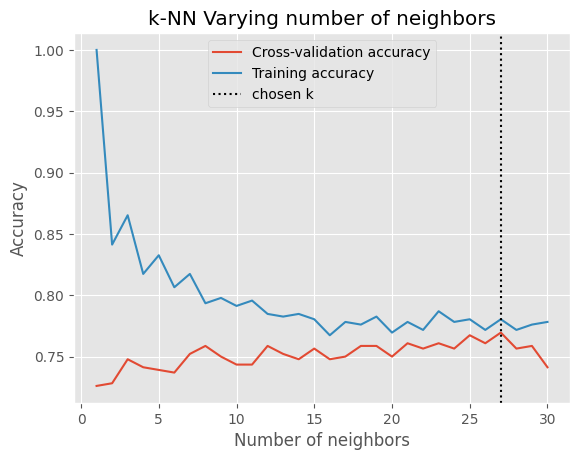

In [6]:
#Generate plot
plt.title('k-NN Varying number of neighbors')
plt.plot(neighbors, cv_accuracy, label='Cross-validation accuracy')
plt.plot(neighbors, train_accuracy, label='Training accuracy')
plt.axvline(best_k, color='k', linestyle=':', label='chosen k')
plt.legend()
plt.xlabel('Number of neighbors')
plt.ylabel('Accuracy')
plt.show()

In [7]:
#Setup a knn classifier with the k chosen by cross-validation
knn = KNeighborsClassifier(n_neighbors=best_k)
#Fit the model
knn.fit(X_train,y_train)

KNeighborsClassifier(n_neighbors=27)

In [8]:
#Get accuracy. Note: In case of classification algorithms score method represents accuracy.
knn.score(X_test,y_test)

0.737012987012987

In [9]:
#import confusion_matrix
from sklearn.metrics import confusion_matrix

#let us get the predictions using the classifier we had fit above
y_pred = knn.predict(X_test)

confusion_matrix(y_test,y_pred)

array([[180,  21],
       [ 60,  47]])

In [10]:
pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'], margins=True)

Predicted,0,1,All
Actual,,,
0,180,21,201
1,60,47,107
All,240,68,308


In [11]:
#import classification_report
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.75      0.90      0.82       201
           1       0.69      0.44      0.54       107

    accuracy                           0.74       308
   macro avg       0.72      0.67      0.68       308
weighted avg       0.73      0.74      0.72       308



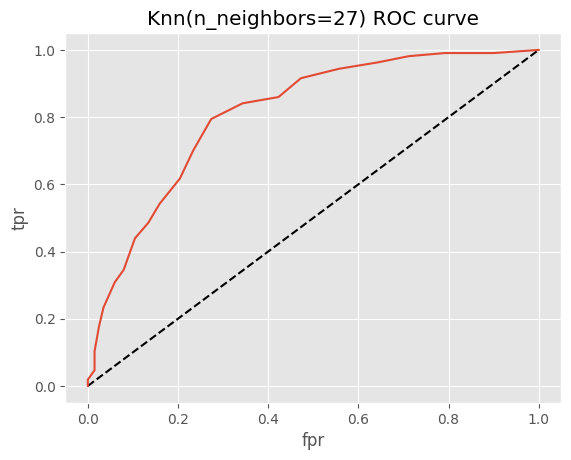

In [12]:
y_pred_proba = knn.predict_proba(X_test)[:,1]

from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

plt.plot([0,1],[0,1],'k--')
plt.plot(fpr,tpr, label='Knn')
plt.xlabel('fpr')
plt.ylabel('tpr')
plt.title('Knn(n_neighbors=%d) ROC curve' % best_k)
plt.show()

In [13]:
#Area under ROC curve
from sklearn.metrics import roc_auc_score
roc_auc_score(y_test,y_pred_proba)

np.float64(0.8106662946947505)

In [14]:
#import GridSearchCV
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
#In case of classifier like knn the parameter to be tuned is n_neighbors.
#The scaler is inside the pipeline so that it is re-fitted on each CV training fold (no leakage),
#and the search only sees the training data.
pipe = Pipeline([('scale', StandardScaler()), ('knn', KNeighborsClassifier())])
param_grid = {'knn__n_neighbors':np.arange(1,50)}
knn_cv= GridSearchCV(pipe,param_grid,cv=5)
knn_cv.fit(X_train_raw,y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('scale', StandardScaler()),
                                       ('knn', KNeighborsClassifier())]),
             param_grid={'knn__n_neighbors': array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34,
       35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49])})

In [15]:
knn_cv.best_score_

np.float64(0.7652173913043477)

In [16]:
knn_cv.best_params_

{'knn__n_neighbors': np.int64(27)}